# Clustering với DBSCAN

Nguồn: https://www.digitalvidya.com/blog/the-top-5-clustering-algorithms-data-scientists-should-know/
![image.png](https://imgur.com/9D6aAF2.gif)

In [18]:
import numpy as np
import matplotlib
from matplotlib import pyplot as plt

np.set_printoptions(precision=3, suppress=True)

## 1. Dữ liệu giả định
(Cùng dữ liệu giả với `03_Demo-kMeans.ipynb`)

In [19]:
np.random.seed(1)
x1,y1 = np.random.normal(loc=2,scale=1,size=50), np.random.normal(loc=5,scale=1,size=50)
x2,y2 = np.random.normal(loc=5,scale=1,size=75), np.random.normal(loc=1,scale=1,size=75)
x3,y3 = np.random.normal(loc=8,scale=1,size=100), np.random.normal(loc=7,scale=1,size=100)

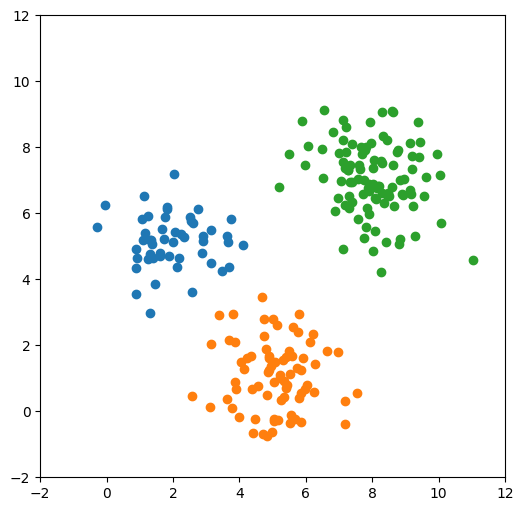

In [20]:
fig = plt.figure(figsize=(6,6))
plt.xlim([-2,12])
plt.ylim([-2,12])

plt.scatter(x1, y1)
plt.scatter(x2, y2)
plt.scatter(x3, y3)
plt.show()

### Ghép nối dữ liệu lại thành 1 tập

In [21]:
dat1 = np.stack([x1,y1]).T
dat1.shape

(50, 2)

In [22]:
dat2 = np.stack([x2,y2]).T
dat3 = np.stack([x3,y3]).T

In [23]:
dat = np.vstack([dat1, dat2, dat3])
dat.shape

(225, 2)

### Sắp ngẫu nhiên các dòng

In [24]:
np.random.seed(2)
np.random.shuffle(dat)

### Kiểm tra lại với biểu đồ scatter

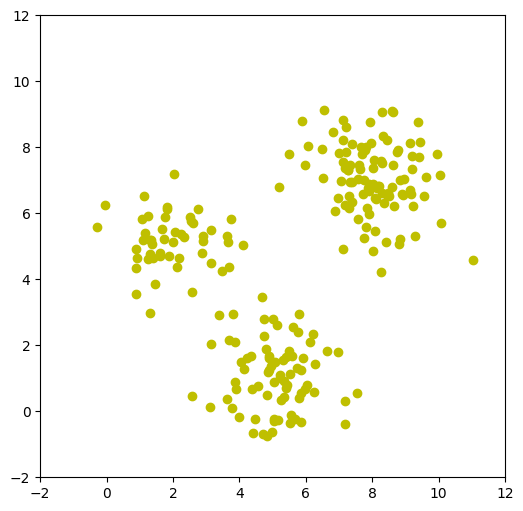

In [25]:
fig = plt.figure(figsize=(6,6))
plt.xlim([-2,12])
plt.ylim([-2,12])

plt.scatter(dat[:,0], dat[:,1], color='y')
plt.show()

## 2. Thực hiện phân cụm bằng DBSCAN

**=== Import lớp DBSCAN từ thư viện sklearn ===**

In [26]:
from sklearn.cluster import DBSCAN

### 2.1. Khởi tạo model và fit vào dữ liệu

In [27]:
# Giả sử chọn epsilon = 1, minPoints = 5
dbscan = DBSCAN(eps=1, min_samples=5)

**=== Thực hiện fit vào dữ liệu ===**

In [28]:
labels = dbscan.fit_predict(dat)

### 2.2. Kiểm tra kết quả các cluster tìm được

**=== Lấy ra nhãn các clusters ===**

In [29]:
clusters = np.unique(labels)

In [30]:
clusters

array([-1,  0,  1,  2])

**=== Đếm xem mỗi cluster có bao nhiêu điểm ===**

In [31]:
for cluster in clusters:
    print(f"Cluster {cluster}: {np.sum(labels == cluster)} điểm")

Cluster -1: 7 điểm
Cluster 0: 98 điểm
Cluster 1: 73 điểm
Cluster 2: 47 điểm


**=== Hiển thị lên biểu đồ ===**

Cluster -1: 7 điểm
Cluster 0: 98 điểm
Cluster 1: 73 điểm
Cluster 2: 47 điểm


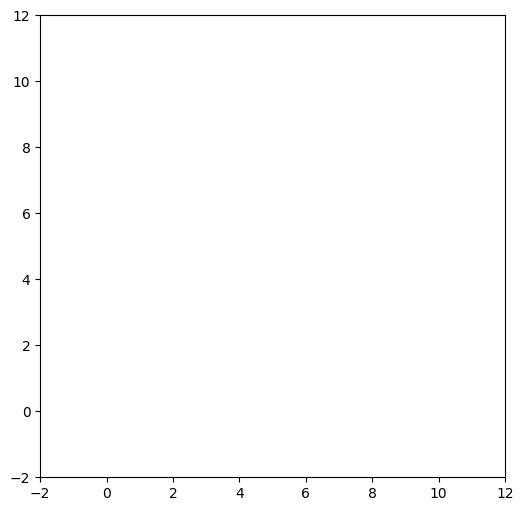

In [32]:
fig = plt.figure(figsize=(6,6))
plt.xlim([-2,12])
plt.ylim([-2,12])

for cluster in clusters:
    print(f"Cluster {cluster}: {np.sum(labels == cluster)} điểm")

plt.show()

In [33]:
print(dat[:5])
print(labels[:20])
print(np.isnan(dat).any())

[[ 5.963  7.467]
 [ 8.956  7.053]
 [ 0.899  3.556]
 [ 4.703 -0.674]
 [ 4.961  1.369]]
[0 0 2 1 1 2 0 1 1 1 1 0 0 2 2 0 2 0 1 2]
False


### 2.3. Tính hiệu suất phân cụm

**=== Thử tính với hàm built-in của Sklearn ===**

In [34]:
from sklearn.metrics import silhouette_score

In [35]:
print("Silhouette Score:", silhouette_score(dat, labels))

Silhouette Score: 0.639460128792222


**=== Tính lại với các cụm không chứa điểm noise ===**

In [37]:
import pandas as pd

In [38]:
# Bỏ đi các samples bị xác định là noise
dat2 = dat[labels != -1]
cluster2 = labels[labels != -1]

In [40]:
# Tạo một list rỗng để chứa hệ số Silhouette của mỗi sample
s_list = []

for i, sample in enumerate(dat2):
    label = cluster2[i]
    
    # Lấy ra các samples khác và nhãn khác
    mask = np.arange(len(dat2)) != i
    other_samples = dat2[mask]
    other_labels = cluster2[mask]
    # Tính khoảng cách từ sample đến tất cả các other_samples
    distances = np.linalg.norm(other_samples - sample, axis=1)
    # Tạo dataframe với 2 cột 'distance' và 'cluster' để dùng groupby tính mean()
    df_temp = pd.DataFrame({
        'distance': distances,
        'cluster': other_labels
    })
    mean_dist = df_temp.groupby('cluster')['distance'].mean()
    # Lấy ra giá trị p, q tương ứng
    p = mean_dist[label]
    # q là khoảng cách trung bình nhỏ nhất đến cụm khác
    q = mean_dist.drop(label).min()
    # Tính ra hệ số Silhouette cho sample
    s = (q - p) / max(p, q)
    s_list.append(s)

In [41]:
# Tính trung bình hệ số Silhouette của tất cả các samples
print("Silhouette Score (bỏ noise):", np.mean(s_list))

Silhouette Score (bỏ noise): 0.6854228250080899


**==> Thử thực hiện lại mà không bỏ giá trị noise?**